#Lab 2.1 Clustering


Clustering is an essential technique in machine learning and data analysis used to group similar items or data points together. Unlike supervised learning, clustering is an unsupervised learning technique, meaning it does not require labeled data. Instead, clustering algorithms analyze the inherent structure of data, helping to reveal natural groupings or patterns within it.

###Why Clustering?
Clustering has a wide range of applications in various fields, such as:

- **Market Segmentation:** Grouping customers based on purchasing behavior or demographics to better tailor marketing strategies.
- **Image Segmentation:** Breaking down an image into distinct regions for tasks like object detection and classification.
- **Anomaly Detection:** Identifying outliers or unusual patterns in data, such as fraud detection in financial transactions.
- **Recommendation Systems:** Grouping similar items or users together to make personalized recommendations, such as on streaming platforms or e-commerce sites.


Don't forget to move the folder to your drive to be able to use it!

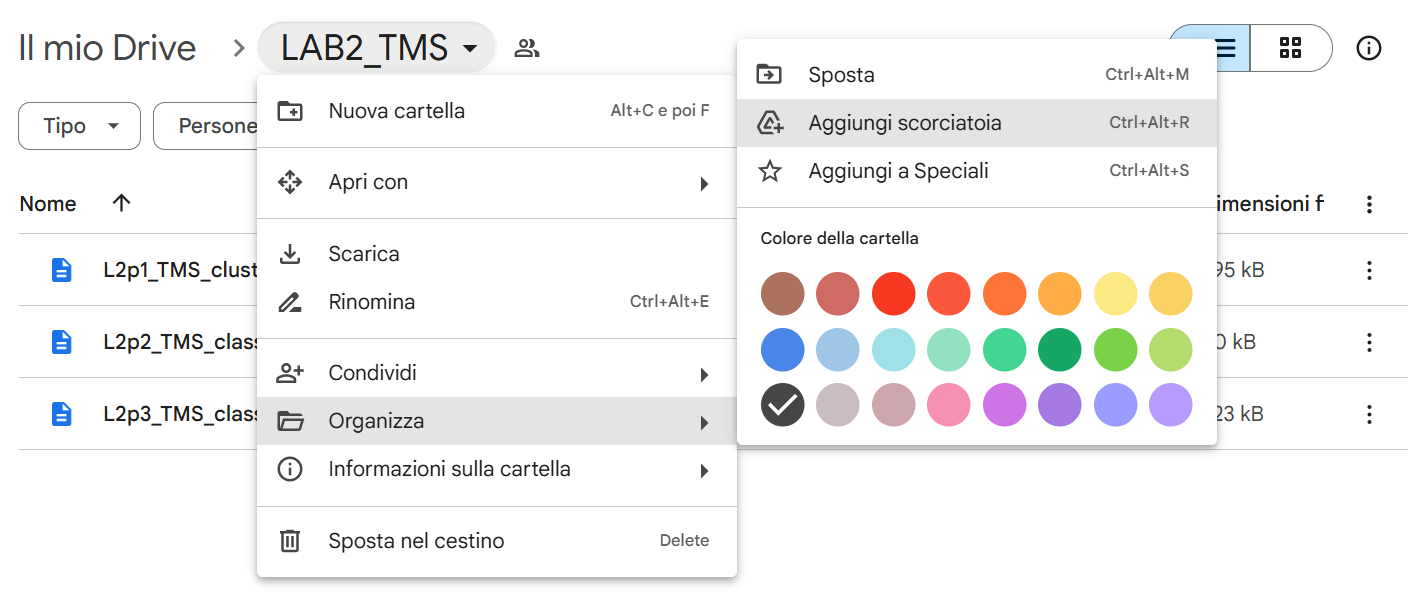

### K-Means

K-Means is a widely-used unsupervised machine learning algorithm for clustering data into groups based on similarity. It is simple, efficient, and versatile, making it a popular choice for exploratory data analysis and segmentation tasks.

The goal of K-Means is to partition a dataset into k distinct clusters, where each data point belongs to the cluster with the nearest centroid (a central point representing the cluster). The algorithm works iteratively to refine these centroids and assign points to the closest cluster, minimizing the intra-cluster variance (the sum of squared distances between points and their cluster centroid).

####Key Steps in K-Means:
- **Initialization:** Choose k initial cluster centroids (randomly or using heuristics).
- **Assignment:** Assign each data point to the nearest centroid based on a distance metric (commonly Euclidean distance).
- **Update:** Recalculate the centroids by averaging the data points assigned to each cluster.
- **Iteration:** Repeat the assignment and update steps until the centroids stabilize or a maximum number of iterations is reached.


K-Means is used in various domains, including: customer segmentation, image compression, anomaly detection, and document clustering.
While powerful, K-Means has limitations, such as sensitivity to the initial choice of centroids and difficulty handling non-spherical clusters. Despite these challenges, its simplicity and effectiveness make it a cornerstone of clustering techniques in machine learning.

In [1]:
!pip install gdown

In [2]:
!gdown 'https://drive.google.com/uc?id=1SwQEuHyO2A9hfSK2rdRH0J-YQ426U_20'

Downloading...
From: https://drive.google.com/uc?id=1SwQEuHyO2A9hfSK2rdRH0J-YQ426U_20
To: /content/spam.csv
100% 479k/479k [00:00<00:00, 23.3MB/s]


In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

spam_data = pd.read_csv('spam.csv')

spam_data['target'] = np.where(spam_data['target'] == 'spam', 1, 0)
print(spam_data.head(10))

X, y = spam_data['text'], spam_data['target']
X_train, X_test, y_train, y_test = train_test_split(
    spam_data['text'], spam_data['target'], random_state=0
)

                                                text  target
0  Go until jurong point, crazy.. Available only ...       0
1                      Ok lar... Joking wif u oni...       0
2  Free entry in 2 a wkly comp to win FA Cup fina...       1
3  U dun say so early hor... U c already then say...       0
4  Nah I don't think he goes to usf, he lives aro...       0
5  FreeMsg Hey there darling it's been 3 week's n...       1
6  Even my brother is not like to speak with me. ...       0
7  As per your request 'Melle Melle (Oru Minnamin...       0
8  WINNER!! As a valued network customer you have...       1
9  Had your mobile 11 months or more? U R entitle...       1


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

# EXERCISE: use a vectorizer from last lab!
vectorizer = TfidfVectorizer()
X_train_transformed = vectorizer.fit_transform(X_train)
X_test_transformed = vectorizer.transform(X_test)

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import v_measure_score
from sklearn.metrics.cluster import adjusted_rand_score

n_clusters = 2

# EXERCISE: fit K-Means to the vectorized dataset
# HINT: look at the documentation of the above imports- google them
km = KMeans(n_clusters=n_clusters, max_iter=100, n_init=100, random_state=42).fit(X_train_transformed)
y_clus = km.predict(X_train_transformed)

Both V-Measure Score and Adjusted Rand Score (ARS) are metrics used to evaluate clustering performance by comparing the resulting clusters to a ground-truth labeling. However, they measure different aspects of clustering quality and have distinct characteristics.

###1. V-Measure Score
The V-Measure Score is an information-theoretic measure that evaluates the balance between two properties of clustering:

- **Homogeneity:** Ensures that each cluster contains only members of a single class (ground-truth label).
- **Completeness:** Ensures that all members of a single class are assigned to the same cluster.

The V-Measure Score is the harmonic mean of homogeneity (H) and completeness (C):

$$
V\text{-}Measure=2\frac{H \cdot C}{H+C}
$$

It's range is [0,1], where 1 means perfect clustering (both homogeneity and completeness are maximized) and 0 means no correspondence between clusters and ground truth.

**Advantages:** Useful for interpreting how well the clusters align with labels in terms of purity and coverage.
Independent of the absolute number of clusters, focusing instead on the relationship between labels and clusters.
**Disadvantages:** Does not account for random chance in clustering assignments.

###2. Adjusted Rand Score (ARS)
The Adjusted Rand Score evaluates the similarity between two clusterings (e.g., predicted clusters and ground truth) by counting pairs of points that are consistently assigned to the same or different clusters in both labelings. It adjusts for chance by considering the expected similarity of random clusterings. To understand the ARS, we should first understand the Rand Index

Given two sets $X$ and $Y$, where each set is divided up into clusters, we define the rand index as:
$$
R = \frac{TP+TN}{TP+TN+FP+FN}
$$
so we can think of this as the number of "disagreements" between $X$ and $Y$.
We then adjust this score by finding the "expected index" (what we would expect the rand index to be in the case of random selection).

$$
ARS
= \frac{Index-Expected Index}{Max Index-Expected Index}
$$

with range [−1,1], where 1 means perfect clustering agreement with ground truth, 0 means clustering is no better than random and negative values that clustering is worse than random chance.

**Advantages:** Adjusts for random chance, providing a robust measure of clustering quality. Useful for comparing clustering methods even when the number of clusters differs significantly.
**Disadvantages:** Requires the number of clusters to match (or approximate) the ground truth labels, making it less flexible than the V-Measure Score.

In [8]:
print(f'''V measure - {v_measure_score(y_clus, y_train)}''')
print(f'''ARI       - {adjusted_rand_score(y_clus, y_train)}''')

V measure - 0.01486551294141215
ARI       - -0.05416793039842444


### Agglomerative clustering

Agglomerative Clustering is a hierarchical clustering algorithm that builds nested clusters by merging or "agglomerating" data points based on their similarity. It is a bottom-up approach to clustering, where each data point starts as its own cluster, and pairs of clusters are merged iteratively until a stopping criterion is met (e.g., all points are in one cluster or a specific number of clusters is reached).

Unlike partitioning methods like K-Means, Agglomerative Clustering does not require specifying the number of clusters in advance and can capture more complex relationships between data points, making it suitable for datasets with non-linear structures.

In [9]:
from sklearn.cluster import AgglomerativeClustering

model = AgglomerativeClustering(n_clusters=5, metric='euclidean')
# EXERCISE: fit to the vectorized data!
model.fit(X_train_transformed.toarray())
y_clus = model.labels_

In [10]:
print(f'''V measure - {v_measure_score(y_clus, y_train)}''')
print(f'''ARI       - {adjusted_rand_score(y_clus,y_train)}''')

V measure - 0.4475061104632287
ARI       - 0.5961961231038662


## Game of Thrones Clustering

We are going use the techniques we've developed so far to understand which character of the GOT books is closer to which. We will show a few visualization techniques, no need to memorize them all, and a method to estimate the number of clusters, called the [Elbow method](https://www.scikit-yb.org/en/latest/api/cluster/elbow.html). We will extract sentences about each character from the text, and remove stop words (like in lab 1!) then cluster each sentence based on their vectorised similarities to one another.

We will be using some dimensionality reduction. Recall what tf-idf is from lab 1:

"Term Frequency-Inverse Document Frequency. $TF(w,d)$ is the number of times word $w$ appears in document $d$. $IDF(w)$ is the rarity of the word in the corpora (collection of documents), calculated as
$$
IDF(w) = log \frac{n}{df(w)}
$$
Where $n$ is the number of documents and $df(w)$ is the number of documents containing $w$. We then calculate the TF-IDF weight, which shows how important a word $w$ is to a document $d$, as follows $$TFIDF(w,d) = TF(w,d)\times IDF(w)$$"

Vectorising a sequence with tf-idf involves finding the tf-idf weight for each term in a vocabulary. This means the vectors are quite *sparse*, lots of the values are 0. As such, we use truncated SVD for dimensionality reduction. This finds the top-$k$ terms which are responsible for the variance, and discards the rest of them. These are the terms that are most important for the clustering process.

In [11]:
!wget -q --show-progress https://www.dropbox.com/s/b8cs502zfcdwbe5/got.zip -O got.zip
!unzip -o got.zip

got.zip             100%[===================>]   1.54M  --.-KB/s    in 0.06s   
Archive:  got.zip
  inflating: got1_nostops.csv        
  inflating: got2_nostops.csv        
  inflating: got3_nostops.csv        
  inflating: got4_nostops.csv        


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import numpy as np

In [13]:
got1 = pd.read_csv('got1_nostops.csv', index_col=0)
got2 = pd.read_csv('got2_nostops.csv', index_col=0)
got3 = pd.read_csv('got3_nostops.csv', index_col=0)
got4 = pd.read_csv('got4_nostops.csv', index_col=0)
got = pd.concat([got1, got2, got3, got4])

In [14]:
got.head()

,Name,Chapter,Text
0,Eddard,1,visitors poured castle gates river gold silver...
1,Eddard,2,summons came hour dawn world still grey alyn s...
2,Eddard,3,found lord ned rose quickly men lannister jory...
3,Eddard,4,eddard stark rode towering bronze doors red ke...
4,Eddard,5,lord arryn death great sadness us lord grand m...


In [15]:
got.groupby('Name').size().sort_values()

,0
Name,
Epilogue,1
The Queenmaker,1
The Prophet,1
The Princess in The Tower,1
The Kraken's Daughter,1
The Iron Captain,1
The Drowned Man,1
The Soiled Knight,1
The Reaver,1


In [16]:
names = ['Arya', 'Bran', 'Brienne', 'Catelyn', 'Cersei',
         'Daenerys', 'Davos', 'Eddard', 'Jaime', 'Jon',
         'Samwell', 'Sansa',  'Theon', 'Tyrion']

got = got[got.Name.isin(names)]

In [17]:
cdict = {'Jon' : 'black',
         'Samwell' : 'tab:purple',
         'Eddard': 'tab:brown',
         'Arya' : 'lime',
         'Catelyn' : 'tab:green',
         'Bran' : 'tab:blue',
         'Sansa' : 'tab:pink',
         'Theon' : 'tab:cyan',
         'Brienne' : 'tab:gray',
         'Davos' : 'tab:olive',
         'Tyrion' : 'tab:red',
         'Jaime' : 'goldenrod',
         'Cersei' : 'gold',
         'Daenerys' : 'tab:orange',}

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

In [19]:
%%time
documents = list(got.Text)
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(documents)

CPU times: user 499 ms, sys: 2.97 ms, total: 502 ms
Wall time: 503 ms


In [20]:
svd = TruncatedSVD(n_components=2)
data = svd.fit_transform(X)
scatter_x = data[:, 0]
scatter_y = data[:, 1]

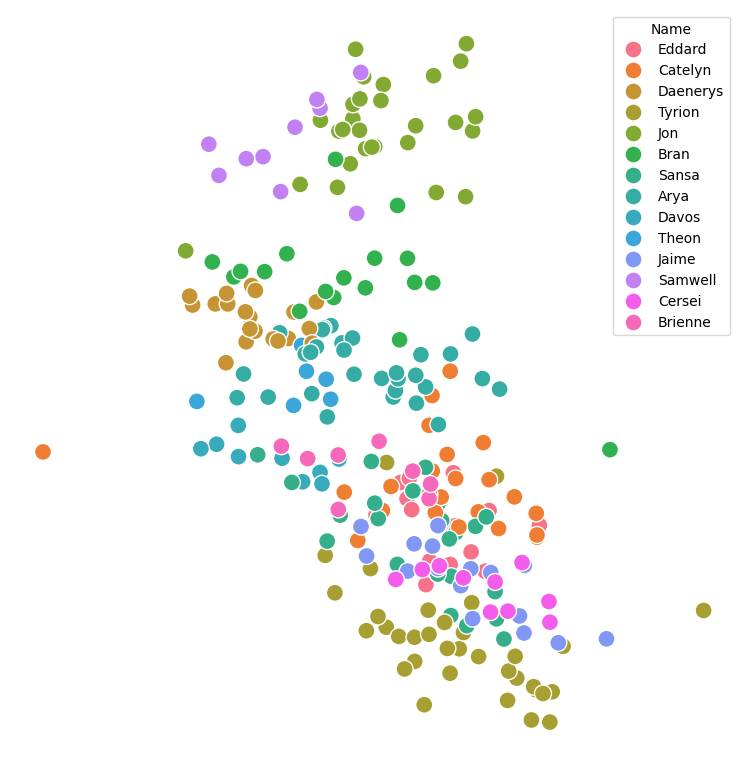

In [21]:
plt.figure(figsize=(8, 8))
sns.scatterplot(x = scatter_x, y=scatter_y, hue=got.Name, s=150)
plt.tight_layout()
plt.axis('off')
plt.show()

In [22]:
# 3D viz
svd = TruncatedSVD(n_components=3)
data = svd.fit_transform(X)
scatter_x = data[:, 0]
scatter_y = data[:, 1]
scatter_z = data[:, 2]
px.scatter_3d(x=scatter_x, y=scatter_y, z=scatter_z, color=got.Name)

T-SNE is another approach to visualising high-dimensional data (https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html)

In [23]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, init='random', learning_rate='auto')
data = tsne.fit_transform(X)
scatter_x = data[:, 0]
scatter_y = data[:, 1]

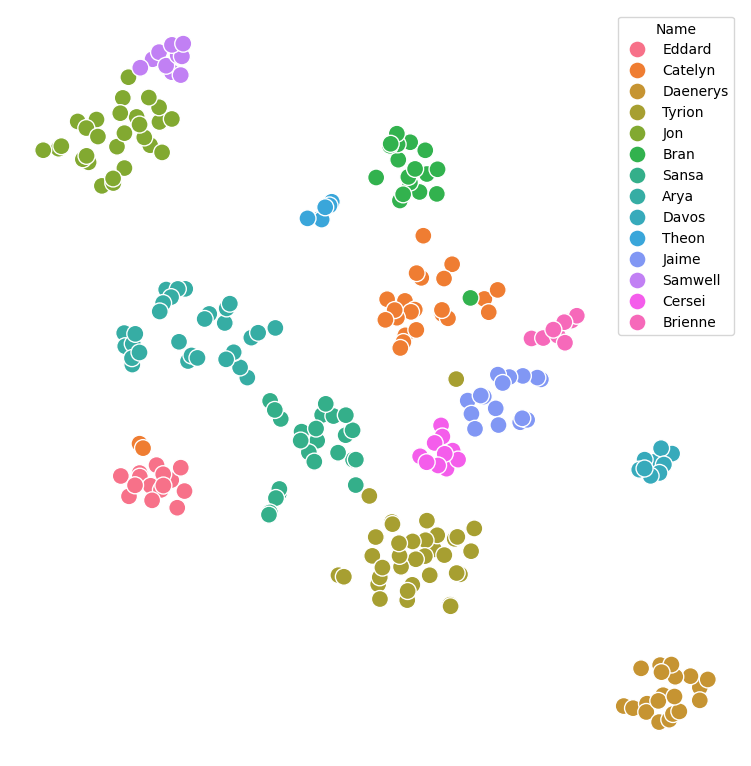

In [24]:
plt.figure(figsize=(8, 8))
sns.scatterplot(x = scatter_x, y=scatter_y, hue=got.Name, s=150)
plt.tight_layout()
plt.axis('off')
plt.show()

In [25]:
# 3D viz
tsne = TSNE(n_components=3, init='random', learning_rate='auto')
data = tsne.fit_transform(X)
scatter_x = data[:, 0]
scatter_y = data[:, 1]
scatter_z = data[:, 2]
px.scatter_3d(x=scatter_x, y=scatter_y, z=scatter_z, color=got.Name)

We now evaluate the performance of our clustering. We have already covered the rand score and the v-measure score, but some of these metrics below will be new to you. Read about them!
<ul>
  <li> Adjusted mutual info score </li>
  <li> Homogeneity score </li>
  <li> Completeness score </li>
  <li> Fowlkes mallows score </li>
</ul>

In [26]:
from sklearn.metrics import (rand_score, adjusted_mutual_info_score,
                             homogeneity_score, completeness_score,
                             v_measure_score, fowlkes_mallows_score)

def score_clustering(true_labels, predicted_labels):
  d = {
      "Rand index": rand_score(true_labels, predicted_labels),
      "Adjusted Mutual Info": adjusted_mutual_info_score(true_labels, predicted_labels),
      "Homogeneity": homogeneity_score(true_labels, predicted_labels),
      "Completeness": completeness_score(true_labels, predicted_labels),
      "V measure": v_measure_score(true_labels, predicted_labels),
      "Fowlkes Mallows": fowlkes_mallows_score(true_labels, predicted_labels),
  }
  for k, v in d.items():
    print(f"{k:21s}: {v}")

In [27]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=len(names), random_state=1)
labels_pred = kmeans.fit_predict(X)
predicted_labels_as_names = [names[i] for i in labels_pred]

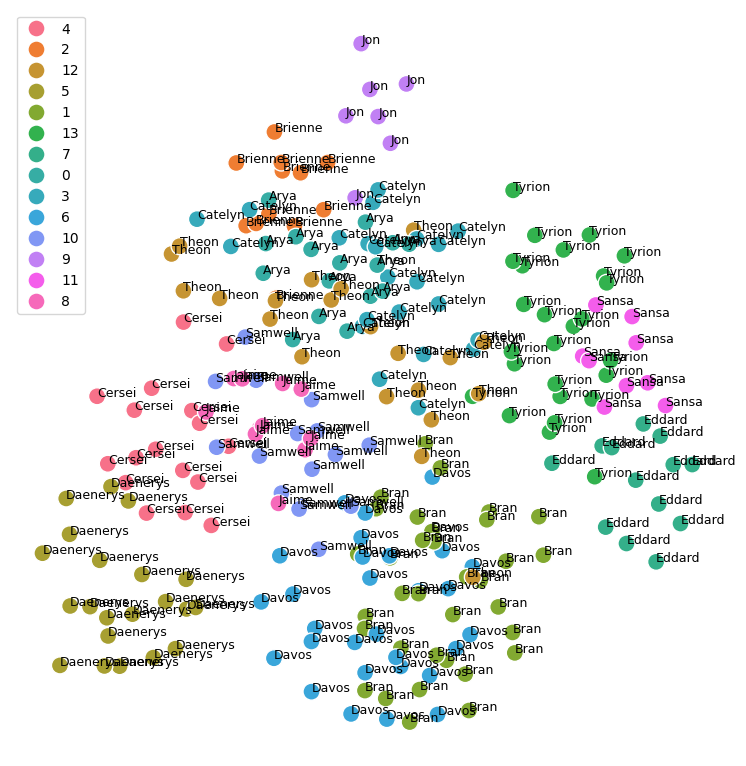

In [28]:
plt.figure(figsize=(8, 8))
sns.scatterplot(x = scatter_x, y=scatter_y, hue=labels_pred.astype(str), s=150,legend="full")
for i, name in enumerate(predicted_labels_as_names):
    plt.text(scatter_x[i], scatter_y[i], name, fontsize=9)
plt.tight_layout()
plt.axis('off')
plt.show()

In [29]:
score_clustering(got.Name, labels_pred)

Rand index           : 0.9802083333333333
Adjusted Mutual Info : 0.9015623692167485
Homogeneity          : 0.9222467395909097
Completeness         : 0.9097674525767646
V measure            : 0.9159645929730406
Fowlkes Mallows      : 0.8807102161156556


## KElbowVisualizer

The KElbowVisualizer is a tool from the Yellowbrick library in Python designed to assist with clustering analysis, specifically in identifying the optimal number of clusters (k) for clustering algorithms like K-Means. It implements the elbow method, which is a popular heuristic for determining the ideal number of clusters by analyzing the rate of decrease in the distortion score (inertia) as the number of clusters increases.

###Key Features:
- **Visualization of the Elbow Method:** Plots the inertia for different values of k to help pinpoint where adding more clusters provides diminishing returns (the "elbow").
- **Support for KMeans and MiniBatchKMeans:** Easily integrates with these clustering models.
- **Automated Detection of the Elbow:** Provides a suggested k using the "knee" point algorithm.

###How It Works:
- **Inertia/Distortion Score:** Measures how tightly data points are grouped around cluster centroids. A lower inertia implies better-defined clusters.
- **The "Elbow Point":** As k increases, inertia decreases. However, the decrease slows down at some point (the elbow), indicating the optimal number of clusters.

In [30]:
from yellowbrick.cluster import KElbowVisualizer
# See https://www.scikit-yb.org/en/latest/api/cluster/elbow.html

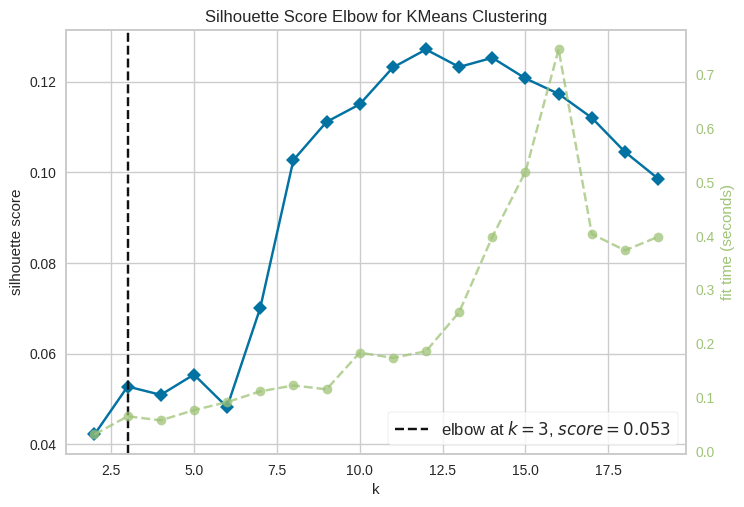

CPU times: user 6.51 s, sys: 43.8 ms, total: 6.56 s
Wall time: 9.42 s


<Axes: title={'center': 'Silhouette Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='silhouette score'>

In [32]:
%%time
model = KMeans(random_state=1)
visualizer = KElbowVisualizer(model, k=(2, 20), metric='silhouette')

# EXERCISE: fit to data
visualizer.fit(X)
visualizer.show()
# This will take a while

In [33]:
visualizer.elbow_value_

np.int64(3)

Interestingly the Elbow Method only finds 3 clusters, possibly one for the North, another for the Lancasters and another for Daenerys substories. Maybe it could be said that our intuitive clustering reasons for this dataset don't match the Elbow Method clustering criteria.

In [34]:
kmeans = KMeans(n_clusters=visualizer.elbow_value_, random_state=1)
elbow_labels_pred = kmeans.fit_predict(X)

In [35]:
score_clustering(got.Name, elbow_labels_pred)

Rand index           : 0.6383578431372549
Adjusted Mutual Info : 0.45143985139806336
Homogeneity          : 0.31835722145661866
Completeness         : 0.8931563875850279
V measure            : 0.4694008944773245
Fowlkes Mallows      : 0.4227017386609469


## K-Means from scratch
Let's have a close look on how K-Means is implemented. Probably you'll find it simpler than you expected. Try a couple of times to solve each exercise before you check the original implementation, [by Juan C Olamendy](https://medium.com/@juanc.olamendy/back-to-basics-mastering-k-means-clustering-with-numpy-ae7e6f1cb9a3#:~:text=At%20its%20heart%2C%20K%2DMeans,2%20and%203%20until%20convergence.).

In [36]:
import numpy as np
import matplotlib.pyplot as plt

class KMeans:
    def __init__(self, n_clusters=3, max_iters=100, random_state=None):
        self.n_clusters = n_clusters
        self.max_iters = max_iters
        self.random_state = random_state
        self.centroids = None

    def fit(self, X):
        if self.random_state:
            np.random.seed(self.random_state)

        # Initialize centroids
        # EXERCISE: initialize the correct number of centroids as randomly chosen points within the dataset
        idx = np.random.choice(len(X), self.n_clusters, replace=False)
        self.centroids = X[idx]

        labels = None
        for _ in range(self.max_iters):
            # Assign clusters
            # EXERCISE: calculate the distances in X
            clusters = self._calculate_distances(X)
            labels = np.argmin(clusters, axis=0)
            # Update centroids
            # EXERCISE: take the mean only of those whose labels == k
            new_centroids = np.array([
                X[labels == k].mean(axis=0)
                for k in range(self.n_clusters)
            ])
            # Check for convergence
            if np.all(self.centroids == new_centroids):
                break

            self.centroids = new_centroids

        return labels

    def predict(self, X):
        return self._calculate_distances(X).argmin(axis=0)

    def _calculate_distances(self, X):
        return np.array([
            np.linalg.norm(X - centroid, axis=1)
            for centroid in self.centroids
        ])

Let's create a toy dataset

In [37]:
# Toy data creation
means = [[2, 2], [8, 3], [3, 6]]
vars = [.5, .1, .2]
N = 100

Xs = []
for i in range(0, len(means)):
    X = np.random.normal(means[i], vars[i], (N, 2))
    Xs.append(X)

X = np.concatenate(Xs)

print(X.shape)

(300, 2)


[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 1 0 1 1 1 1 0 1 1 0 1 1 1 1 0 1 1 1 1 1
 1 1 1 0 0 1 0 1 1 0 0 1 0 1 1 1 1 1 1 1 0 1 1 1 0 1 0 0 0 0 1 1 0 1 0 1 1
 1 1 1 1 1 0 1 1 0 0 1 1 1 0 0 1 1 1 0 1 1 1 0 0 0 1 0 1 1 1 1 1 1 1 1 0 0
 1 1 1 1]


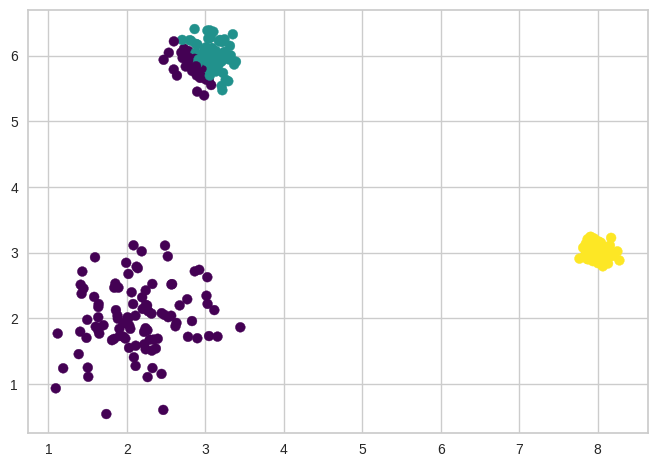

In [38]:

kmeans = KMeans(n_clusters=3, random_state=42, max_iters=1)
labels = kmeans.fit(X)
print(labels)

cmap = plt.get_cmap('hot')
plt.set_cmap(cmap)
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=50)
plt.show()

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1]


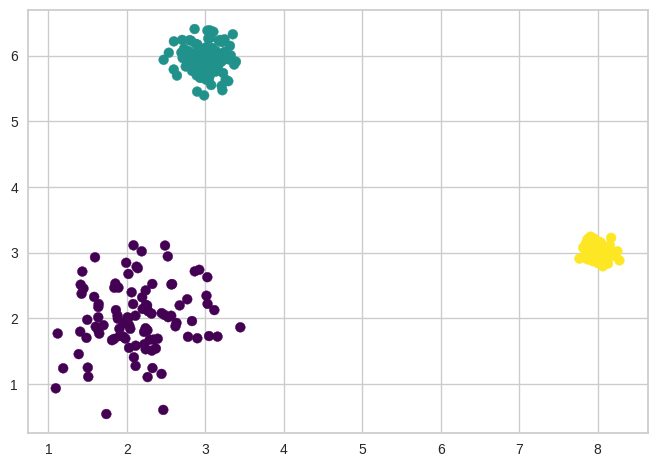

In [39]:
kmeans = KMeans(n_clusters=3, random_state=42, max_iters=3)
labels = kmeans.fit(X)
print(labels)

cmap = plt.get_cmap('hot')
plt.set_cmap(cmap)
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=50)
plt.show()

## K-Means over a Doc2Vec representation

Using K-Means clustering over a Doc2Vec representation combines two powerful techniques for natural language processing (NLP) and unsupervised learning. This approach is widely used to group similar documents, such as articles, reviews, or any text data, into clusters based on semantic similarity.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 37.5 MB/s eta 0:00:00


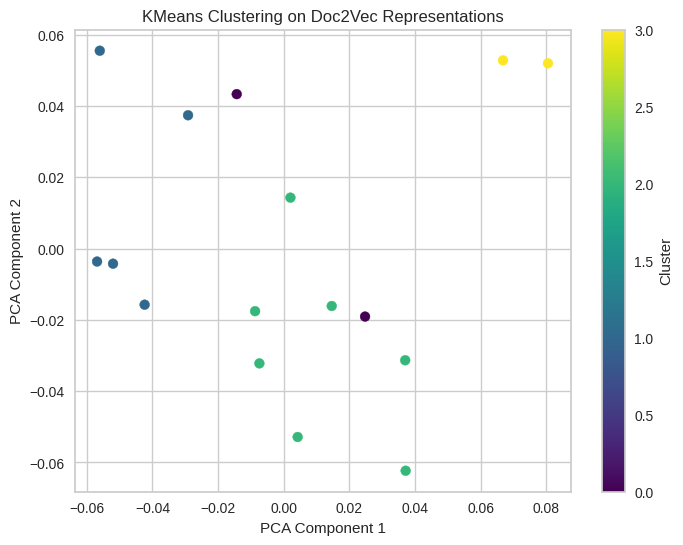

In [41]:
# Step 1: Load and Preprocess the Data
!pip install gensim
from gensim.models.doc2vec import Doc2Vec, TaggedDocument
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# Example of toy text data
documents = [
    "Clustering is a powerful tool in machine learning.",
    "Doc2Vec creates vector representations of documents.",
    "KMeans is a popular clustering algorithm.",
    "Machine learning applications include clustering and classification.",
    "Vectorization transforms text into numerical format.",
    "Neural networks are another type of machine learning model.",
    "Artificial intelligence is transforming the healthcare industry with predictive analytics.",
    "Quantum computing has the potential to solve complex problems faster than traditional computers.",
    "The rise of blockchain technology is revolutionizing data security and transparency.",
    "Electric vehicles are becoming more popular due to their environmental benefits and reduced operating costs.",
    "Augmented reality is enhancing user experiences in gaming and education.",
    "The Internet of Things connects devices to create smart homes and cities.",
    "Renewable energy sources like solar and wind are crucial for a sustainable future.",
    "Cybersecurity measures are essential to protect sensitive data from potential breaches.",
    "5G technology is enabling faster internet speeds and more reliable connections globally.",
    "Robotics is automating repetitive tasks, increasing efficiency across various industries.",
]

# Preprocessing: Tagging documents
tagged_docs = [TaggedDocument(doc.split(), [i]) for i, doc in enumerate(documents)]

# Step 2: Train a Doc2Vec Model
model = Doc2Vec(tagged_docs, vector_size=10, window=2, min_count=1, workers=4, epochs=20)

# Infer vector representations of documents
doc_vectors = np.array([model.infer_vector(doc.split()) for doc in documents])

# Step 3: Apply Clustering (e.g., KMeans)
n_clusters = 4
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
labels = kmeans.fit_predict(doc_vectors)

# Step 4: Visualize Clusters (Optional)
# Reduce dimensionality with PCA
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(doc_vectors)

# Scatter plot of clusters
plt.figure(figsize=(8, 6))
scatter = plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1], c=labels, cmap='viridis', s=50)
plt.colorbar(scatter, label='Cluster')
plt.title('KMeans Clustering on Doc2Vec Representations')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()


Let's see if actually the clusters identified capture ideas that are clear also to us!

In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer
from collections import Counter

# Step 1: Group Documents by Cluster
clustered_docs = {i: [] for i in range(n_clusters)}
for i, label in enumerate(labels):
    clustered_docs[label].append(documents[i])

# Step 2: Extract Keywords for Each Cluster
def extract_keywords(docs, top_n=5):
    """Extract top-n keywords using TF-IDF"""
    vectorizer = TfidfVectorizer(stop_words='english')
    X = vectorizer.fit_transform(docs)
    feature_array = np.array(vectorizer.get_feature_names_out())
    tfidf_sorting = np.argsort(X.toarray().sum(axis=0))[::-1]
    top_keywords = feature_array[tfidf_sorting][:top_n]
    return top_keywords

# Analyze keywords for each cluster
topics = {}
for cluster_id, docs in clustered_docs.items():
    keywords = extract_keywords(docs)
    topics[cluster_id] = keywords

# Step 3: Display Topics
for cluster_id, keywords in topics.items():
    print(f"Cluster {cluster_id} Topic Keywords: {', '.join(keywords)}")

Cluster 0 Topic Keywords: type, networks, neural, learning, machine
Cluster 1 Topic Keywords: vectorization, tool, transforms, text, powerful
Cluster 2 Topic Keywords: faster, algorithm, kmeans, popular, clustering
Cluster 3 Topic Keywords: machine, learning, clustering, classification, applications
